# Los datos, solos, no deciden

**Aprendizaje Automático · Doctorado en Ingeniería · Universidad de Talca**
Clase 2, unidad 1 · Genera la figura de la lámina «El conteo»

---

La clase afirma algo que suena exagerado: que una muestra de entrenamiento **no
elimina casi nada** del espacio de funciones posibles, y que las hipótesis que
sobreviven discrepan entre sí de todas las formas posibles sobre lo no
observado.

Aquí lo verificamos **por enumeración exhaustiva**, no por argumento. Con cuatro
atributos binarios el espacio completo tiene $2^{16} = 65\,536$ funciones, que
caben en memoria y se recorren una por una. El resultado no es una estimación:
es un conteo.

## Lo que vamos a mostrar, en tres pasos

| Paso | $\mathcal{H}$ | Qué sale |
|---|---|---|
| 1 | Todas las funciones | La fracción que predice 1 en un punto no visto es **exactamente** $1/2$ |
| 2 | Solo conjunciones, y el concepto **es** una conjunción | La muestra sí informa: el sesgo paga |
| 3 | Solo conjunciones, y el concepto **no** lo es | No sobrevive ninguna hipótesis: el sesgo se refuta |

Los pasos 2 y 3 son las dos caras de la misma moneda, y juntos son No Free
Lunch en miniatura: el sesgo que hace posible aprender es el mismo que puede
estar equivocado.

## 1. Entorno

Se declara para que un tercero pueda reproducir el resultado exacto. Es el ítem 2
de la lista de cotejo de los talleres.

In [1]:
import sys, platform, itertools
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

print("Python     ", sys.version.split()[0], "|", platform.system(), platform.machine())
print("numpy      ", np.__version__)
print("matplotlib ", matplotlib.__version__)

Python      3.12.14 | Darwin arm64
numpy       2.2.6
matplotlib  3.10.9


## 2. Parámetros

`N_ATRIBUTOS = 4` es el mayor valor que permite enumerar el espacio completo sin
muestrear: con cinco serían $2^{32}$ funciones, y habría que estimar en lugar de
contar. El punto de este cuaderno es que el resultado es exacto.

In [2]:
SEMILLA = 11
N_ATRIBUTOS = 4                      # -> 2**4 = 16 entradas posibles
N_OBSERVADOS = 10                    # casos de la muestra S

N_ENTRADAS = 2 ** N_ATRIBUTOS
N_FUNCIONES = 2 ** N_ENTRADAS

print(f"Entradas posibles:  {N_ENTRADAS}")
print(f"Funciones posibles: {N_FUNCIONES:,}")
print(f"Casos observados:   {N_OBSERVADOS}")

Entradas posibles:  16
Funciones posibles: 65,536
Casos observados:   10


## 3. El espacio de entrada y la muestra

**Protocolo.** Los índices observados se sortean una sola vez con la semilla
declarada, y los mismos se usan en los tres pasos. Lo único que cambia entre
pasos es la función objetivo y el espacio de hipótesis, que es justamente lo que
queremos aislar.

In [3]:
entradas = np.array(list(itertools.product([0, 1], repeat=N_ATRIBUTOS))) # Matriz de entradas

rng = np.random.default_rng(SEMILLA) # Generador de números aleatorios reproducible
observados = np.sort(rng.choice(N_ENTRADAS, N_OBSERVADOS, replace=False)) # Índices de entradas observadas (sin reemplazo)
no_observados = np.array([i for i in range(N_ENTRADAS) if i not in set(observados)]) # Índices de entradas no observadas

print("Índices observados:    ", observados)
print("Índices no observados: ", no_observados)

Índices observados:     [ 0  1  2  4  6  7  9 11 13 14]
Índices no observados:  [ 3  5  8 10 12 15]


## 4. Los dos espacios de hipótesis

El completo se genera leyendo cada entero de 0 a 65 535 como un vector de 16 bits.

El restringido son las **conjunciones de literales**: reglas de la forma
«$x_1 = 1$ y $x_3 = 0$». Cada atributo aparece positivo, negado o ausente, de
modo que hay $3^4 = 81$. Esa pequeñez —81 frente a 65 536— es el sesgo, y se
enuncia en una frase: *el concepto es una conjunción*.

In [4]:
# Espacio completo: cada función es un vector de 16 bits.
todas = ((np.arange(N_FUNCIONES)[:, None] >> np.arange(N_ENTRADAS)) & 1) ## Matriz de todas las funciones posibles

def conjuncion(patron):
    """patron[i] in {0, 1, None}: valor exigido al atributo i, o None si es libre."""
    salida = np.ones(N_ENTRADAS, dtype=int) # Vector de 1s
    for i, v in enumerate(patron): ## Recorremos cada atributo del patrón
        if v is not None: ## Si el valor del atributo no es libre (None), filtramos las entradas
            salida &= (entradas[:, i] == v).astype(int) ## Aplicamos el filtro
    return salida

patrones = list(itertools.product([0, 1, None], repeat=N_ATRIBUTOS)) ## Generamos todos los patrones posibles de 4 atributos, donde cada atributo puede ser 0, 1 o None (libre)
conjunciones = np.array([conjuncion(p) for p in patrones]) ## Generamos todas las funciones de conjunción a partir de los patrones

print(f"Espacio completo:  {len(todas):,} funciones")
print(f"Conjunciones:      {len(conjunciones)} funciones")

Espacio completo:  65,536 funciones
Conjunciones:      81 funciones


In [ ]:
def consistentes(espacio, objetivo):
    """Las hipótesis del espacio que coinciden con el objetivo en lo observado."""
    return espacio[np.all(espacio[:, observados] == objetivo[observados], axis=1)] ## Filtramos las funciones que coinciden con el objetivo en los índices observados

def fraccion_que_predice_1(cons): ## Calcula la fracción de consistentes que predicen 1 en cada punto no observado
    """Por cada punto no observado, qué fracción de las consistentes predice 1."""
    if len(cons) == 0:
        return None
    return cons[:, no_observados].mean(axis=0)

## 5. Paso 1 — Sin restricciones, la muestra no dice nada

Tomamos como objetivo una conjunción, que es la que usaremos en todo el cuaderno:

$$f(x) \;=\; [\,x_1 = 1\,] \wedge [\,x_3 = 0\,]$$

El conteo predicho por la clase es $2^{\,16-10} = 2^{6} = 64$ hipótesis
consistentes.

In [ ]:
# El concepto verdadero: x1 = 1 y x3 = 0  (índices 0 y 2, contando desde cero).
objetivo_conj = conjuncion((1, None, 0, None)) # Generamos la función objetivo como una conjunción de los atributos 1 y 3 (índices 0 y 2), donde x1 = 1 y x3 = 0, y los demás atributos son libres (None).

cons_todas = consistentes(todas, objetivo_conj) # Filtramos las funciones consistentes con el objetivo en los casos observados
fr_todas = fraccion_que_predice_1(cons_todas)

print(f"Hipótesis consistentes: {len(cons_todas):,}") ## Número de hipótesis consistentes con el objetivo en los casos observados
print(f"Predicho por el conteo: {2 ** (N_ENTRADAS - N_OBSERVADOS):,}\n") ## Número de funciones consistentes con el objetivo en los casos observados, calculado como 2^(N_ENTRADAS - N_OBSERVADOS)
print(f"{'entrada':>18} {'fracción que predice 1':>24}") ## Encabezado de la tabla
print("-" * 44)
for idx, f in zip(no_observados, fr_todas):
    print(f"{str(entradas[idx]):>18} {f:>24.3f}")

Hipótesis consistentes: 64
Predicho por el conteo: 64

           entrada   fracción que predice 1
--------------------------------------------
         [0 0 1 1]                    0.500
         [0 1 0 1]                    0.500
         [1 0 0 0]                    0.500
         [1 0 1 0]                    0.500
         [1 1 0 0]                    0.500
         [1 1 1 1]                    0.500


**Exactamente 0,5 en todos los puntos.** No aproximadamente: exactamente, y por
la razón que da la clase —las funciones consistentes vienen emparejadas, y cada
par difiere solo en el punto que se mire.

Y nótese que esto ocurre **aunque el concepto verdadero sea simple**. La
simplicidad del objetivo no ayuda en absoluto: lo que falta no es una función
sencilla, es un supuesto que privilegie las funciones sencillas.

## 6. Paso 2 — Con el sesgo correcto, la muestra informa

In [9]:
cons_conj = consistentes(conjunciones, objetivo_conj)
fr_conj = fraccion_que_predice_1(cons_conj) # Calcula la fracción de consistentes que predicen 1 en cada punto no observado

print(f"Conjunciones consistentes: {len(cons_conj)} de {len(conjunciones)}\n")
print(f"{'entrada':>18} {'todas':>10} {'conjunciones':>16} {'verdad':>9}")
print("-" * 56)
for k, idx in enumerate(no_observados):
    print(f"{str(entradas[idx]):>18} {fr_todas[k]:>10.3f} "
          f"{fr_conj[k]:>16.3f} {objetivo_conj[idx]:>9d}")

Conjunciones consistentes: 2 de 81

           entrada      todas     conjunciones    verdad
--------------------------------------------------------
         [0 0 1 1]      0.500            0.000         0
         [0 1 0 1]      0.500            0.000         0
         [1 0 0 0]      0.500            0.500         1
         [1 0 1 0]      0.500            0.000         0
         [1 1 0 0]      0.500            0.500         1
         [1 1 1 1]      0.500            0.000         0


Las fracciones ya no son 0,5: en varios puntos **todas** las hipótesis
supervivientes coinciden, y coinciden con la verdad. La muestra pasó de muda a
informativa.

Lo único que cambió fue el espacio de hipótesis. Los datos son los mismos.

## 7. Figura

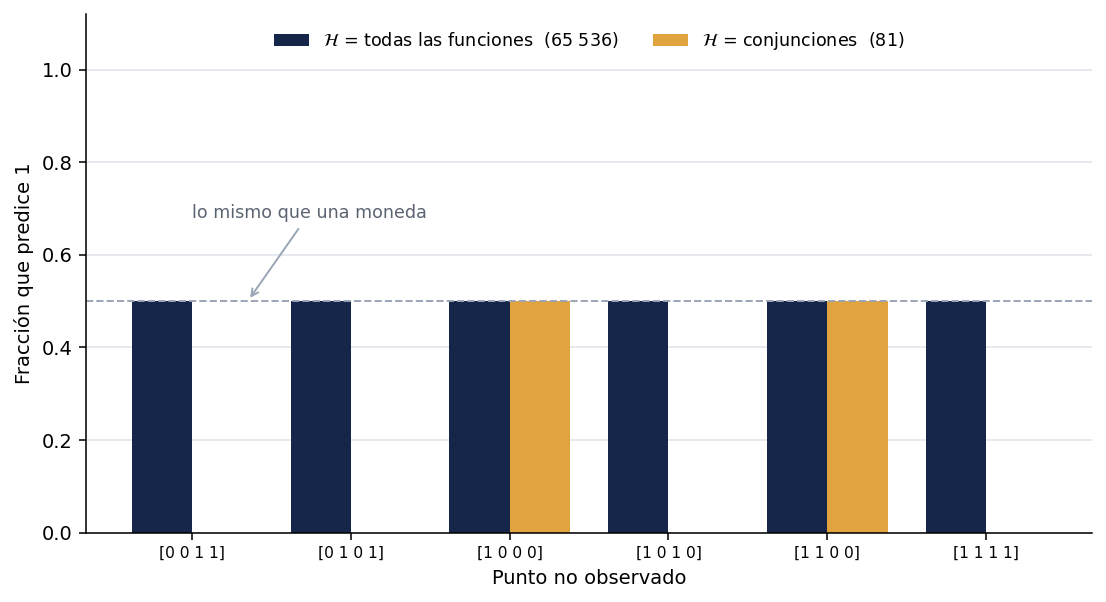

In [10]:
#| label: fig-conteo
#| fig-cap: "Fracción de hipótesis consistentes que predice 1 en cada punto no observado."
x = np.arange(len(no_observados))
ancho = 0.38

fig, ax = plt.subplots(figsize=(8, 4.4), dpi=140)
ax.bar(x - ancho / 2, fr_todas, ancho, color="#16264A",
       label=r"$\mathcal{H}$ = todas las funciones  (65 536)")
ax.bar(x + ancho / 2, fr_conj, ancho, color="#E0A33E",
       label=r"$\mathcal{H}$ = conjunciones  (81)")

ax.axhline(0.5, color="#9AA5B5", ls="--", lw=1)
ax.annotate("lo mismo que una moneda", xy=(0.35, 0.5), xytext=(0.0, 0.68),
            fontsize=9, color="#5B6472",
            arrowprops=dict(arrowstyle="->", color="#9AA5B5", lw=1))

ax.set_xticks(x)
ax.set_xticklabels([str(entradas[i]) for i in no_observados], fontsize=8)
ax.set_xlabel("Punto no observado")
ax.set_ylabel("Fracción que predice 1")
ax.set_ylim(0, 1.12)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#E6EAF0", lw=1)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper center", ncol=2, fontsize=9)

fig.tight_layout()
fig.savefig("conteo_de_hipotesis.png", dpi=200, bbox_inches="tight")
plt.show()

## 8. Paso 3 — El mismo sesgo, cuando está equivocado

El sesgo no es gratis. Si el concepto verdadero **no** es una conjunción, el
espacio restringido no lo contiene, y eso tiene una consecuencia observable.

In [ ]:
r = np.random.default_rng(SEMILLA) ## Generador de números aleatorios reproducible
sin_estructura = 0 
for _ in range(200) ## Generamos 200 funciones objetivo aleatorias:
    obj = r.integers(0, 2, N_ENTRADAS) 
    if len(consistentes(conjunciones, obj)) == 0:
        sin_estructura += 1

print(f"De 200 funciones objetivo aleatorias, en {sin_estructura} no sobrevive")
print(f"ninguna conjunción: {100 * sin_estructura / 200:.0f} % de los casos.")
print()
print("En el espacio completo, en cambio, siempre sobreviven exactamente 64.")

De 200 funciones objetivo aleatorias, en 196 no sobrevive
ninguna conjunción: 98 % de los casos.

En el espacio completo, en cambio, siempre sobreviven exactamente 64.


Cuando el sesgo es incorrecto, **el método falla ruidosamente**: no queda
ninguna hipótesis consistente y el algoritmo no puede devolver nada.

Eso, que parece un defecto, es una virtud: un sesgo refutable por los datos es
un supuesto científico. Lo peligroso es el sesgo que *siempre* devuelve una
respuesta —una red suficientemente grande, por ejemplo— porque entonces nunca se
entera de estar equivocado, y usted tampoco.

Es la lección de la segunda parte de la clase: elegir un sesgo es apostar, y el
mérito no está en no apostar sino en declarar la apuesta y poder perderla.

## 9. Bitácora

**Decisiones tomadas**

1. *Cuatro atributos binarios.* Es el mayor tamaño que permite enumerar el
   espacio completo. Con cinco habría que muestrear, y eso debilitaría el
   argumento: el punto es que el 0,5 es exacto y no una estimación.
2. *Conjunciones como espacio restringido.* Es el ejemplo clásico de espacio con
   sesgo enunciable en una frase. Cualquier otra restricción serviría igual.
3. *La función objetivo del paso 2 es una conjunción.* Deliberado: para que el
   contraste sea visible, el sesgo tiene que ser correcto. El paso 3 muestra el
   caso contrario y evita que el cuaderno quede vendiendo el sesgo como gratuito.
4. *Sin reporte de variabilidad.* Aquí no hay ninguna: la fracción 0,5 es un
   resultado exacto del conteo, no un promedio muestral. La sección 10 lo
   comprueba sobre varias semillas en vez de reportar una desviación que sería
   idénticamente cero.

**Decisión alternativa descartada** — ítem 7 de la lista de cotejo

Se consideró usar árboles de decisión de profundidad ≤ 2 como espacio
restringido. **Se descartó** porque enumerarlos exige bastante más código sin
aportar nada al argumento: lo que importa es que el espacio sea pequeño y que su
sesgo se pueda enunciar, no cuál sea. La conjunción se explica en una línea y el
árbol no.

**Uso de asistentes de IA**

Declarar aquí en qué parte del trabajo se usaron, según la regla operativa del
módulo.

## 10. Verificación

El resultado central no depende de la semilla ni de la función objetivo. Si
dependiera, el argumento de la clase sería falso.

In [12]:
for semilla in range(1, 8):
    r = np.random.default_rng(semilla)
    obs = np.sort(r.choice(N_ENTRADAS, N_OBSERVADOS, replace=False))
    no_obs = np.array([i for i in range(N_ENTRADAS) if i not in set(obs)])
    obj = r.integers(0, 2, N_ENTRADAS)
    cons = todas[np.all(todas[:, obs] == obj[obs], axis=1)]
    assert len(cons) == 2 ** (N_ENTRADAS - N_OBSERVADOS)
    np.testing.assert_allclose(cons[:, no_obs].mean(axis=0), 0.5, atol=1e-12)

print("Verificado sobre 7 semillas:")
print("  - sobreviven siempre 2**(16-10) = 64 hipótesis;")
print("  - la fracción que predice 1 es exactamente 0,5 en todo punto no observado.")

Verificado sobre 7 semillas:
  - sobreviven siempre 2**(16-10) = 64 hipótesis;
  - la fracción que predice 1 es exactamente 0,5 en todo punto no observado.
